# PDAN8412w - Final Portfolio: CNN Facial Image Recognition
##### Dataset: FER2013 Facial Expression - https://www.kaggle.com/datasets/msambare/fer2013
##### Convolutional Neural Network (CNN) Image Recognition.

**Spark (PySpark)** will be used for the data-processing and analysis stages, including:

- Loading and working with the image dataset and metadata
- Data cleaning and validation
- Checking missing, invalid and duplicate records
- Calculating class counts and distributions
- Calculating summary statistics for the image data
- Supporting data transformation and preparation before CNN modelling

Python libraries will be used for:
- Data manipulation and numerical operations
- Data visualization
- CNN model development and training
- Model prediction and evaluation

The following libraries will be used:

- **PySpark** – for distributed data processing, cleaning, exploration and transformation
- **Pandas** – for handling datasets and supporting data analysis
- **NumPy** – for numerical operations and image data preparation
- **Matplotlib and Seaborn** – for data visualization
- **TensorFlow/Keras** – to build and train the CNN model
- **Scikit-learn** – for model evaluation and classification metrics


In [2]:

# Imports - Spark for EDA (requirement), TensorFlow for CNN
# Import libraries
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import hashlib

from io import BytesIO
from PIL import Image
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StringType,
    StructType,
    StructField,
    BooleanType,
    IntegerType
)  
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import cosine_similarity

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


# ============================================================
# NOTEBOOK 2 - INDEPENDENT SPARK SESSION
# Purpose: Data cleaning completion and visualization
# ============================================================

import os
import sys

# Python configuration
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Hadoop configuration
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

# Limit Spark resource usage
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("FER2013_Visualization")
    .master("local[2]")
    .config("spark.driver.memory", "2g")
    .config("spark.executor.memory", "2g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.default.parallelism", "4")
    .config("spark.python.worker.reuse", "true")
    .getOrCreate()
)

print("Independent Spark session initialized.")
print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)

spark


Independent Spark session initialized.
Spark version: 4.1.3
Application: FER2013_Visualization


## 1. DATA CLEANING
**The Plan:**

The cleaning checks include:
- Loading and inspecting the FER2013 image metadata using PySpark;
- Verifying that more than 10,000 records are available;
- Validating image dimensions, data types and labels;
- Checking for missing values and corrupt images;
- Identifying duplicate images using image hashes;
- Checking that training and test data are appropriately separated;
- Normalising pixel values from 0–255 to 0–1 for CNN training; and
- Maintaining an audit of records removed during cleaning.


In [3]:
# Load image dataset
file_path = r"archive_CNN"

df_spark = (
    spark.read
    .format("binaryFile")
    .option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*.jpg")
    .load(file_path)
)

df_spark = df_spark.withColumnRenamed(
    "path", "image_path"
)

# Extract dataset split and labels
df_spark = df_spark \
    .withColumn(
        "dataset_split",
        F.regexp_extract(
            F.col("image_path"),
            r"[\\/](train|test)[\\/]", 1
        )
    ) \
    .withColumn(
        "label",
        F.regexp_extract(
            F.col("image_path"),
            r"[\\/](angry|happy|neutral|sad)[\\/]", 1
        )
    )

# Keep the four selected classes
df_spark = df_spark.filter(
    F.col("label").isin(
        "angry", "happy", "neutral", "sad"
    )
)

print("Dataset successfully reloaded.")
print(f"Selected records: {df_spark.count()}")

Dataset successfully reloaded.
Selected records: 26217


In [4]:

# ============================================================
# DATA CLEANING - REMOVE DUPLICATES
# ============================================================

# Generate image hashes
df_hashed = df_spark.withColumn(
    "image_hash",
    F.md5(F.col("content"))
)

# Remove exact duplicate images
df_clean = df_hashed.dropDuplicates(
    ["image_hash"]
).cache()

# Count cleaned records
cleaned_records = df_clean.count()

print("\nDuplicate removal results:")
print(f"Original records: {df_spark.count()}")
print(f"Cleaned records: {cleaned_records}")
print(
    f"Duplicate records removed: "
    f"{df_spark.count() - cleaned_records}"
)

print("\nCleaned dataset is ready.")



Duplicate removal results:
Original records: 26217
Cleaned records: 25512
Duplicate records removed: 705

Cleaned dataset is ready.


In [5]:
df_clean = (
    df_clean
    .withColumn("width", F.lit(48))
    .withColumn("height", F.lit(48))
    .withColumn("grayscale", F.lit(True))
)

## 2. Data Explorations

**The Plan**

The exploration includes:
- Analysing the number and percentage of images in each facial-expression category using pyspark;
- Calculating pixel intensity statistics, including the mean and standard deviation;
- Examining image dimensions and grayscale consistency;
- Identifying unusually dark or bright images;
- Displaying sample images from each category to inspect facial variation; and
- Examining similarities between expression categories to identify potential classification challenges.


DATA EXPLORATION - FER2013

Total cleaned records: 25512

Class distribution:
+-------+-----+----------+
|label  |count|percentage|
+-------+-----+----------+
|angry  |4738 |18.57     |
|happy  |8799 |34.49     |
|neutral|6052 |23.72     |
|sad    |5923 |23.22     |
+-------+-----+----------+


Largest class count: 8799
Smallest class count: 4738
Class imbalance ratio: 1.86

Image exploration sample:
Total cleaned images: 25512
Images selected: 1302
Percentage sampled: 5.10%

Dimension summary:
+---------+---------+---------+----------+----------+----------+
|min_width|max_width|avg_width|min_height|max_height|avg_height|
+---------+---------+---------+----------+----------+----------+
|       48|       48|     48.0|        48|        48|      48.0|
+---------+---------+---------+----------+----------+----------+


Grayscale distribution:
+---------+-----+
|grayscale|count|
+---------+-----+
|     true| 1302|
+---------+-----+


Pixel intensity statistics:
+----------------------+-----

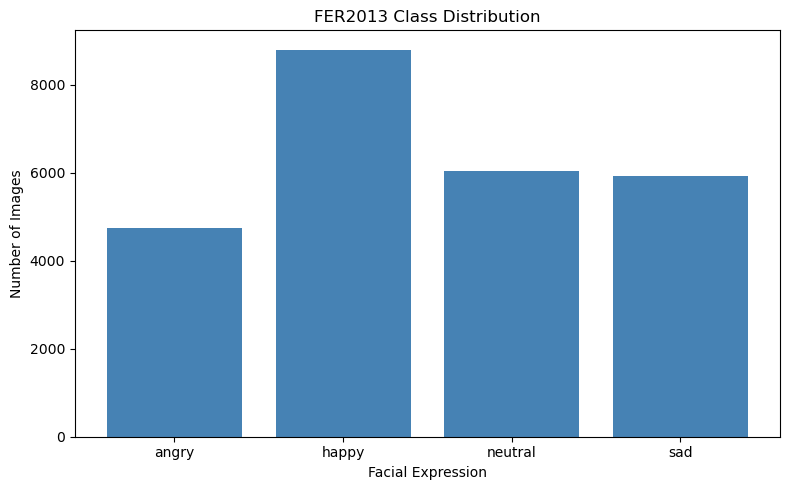

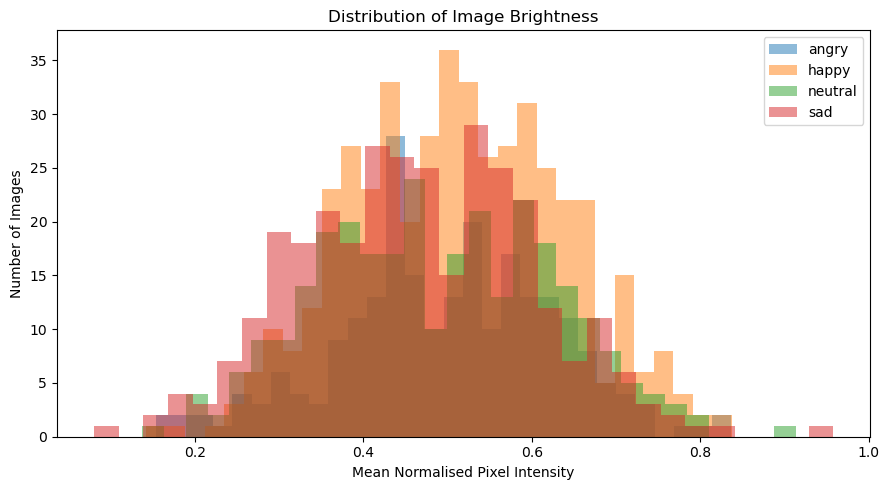

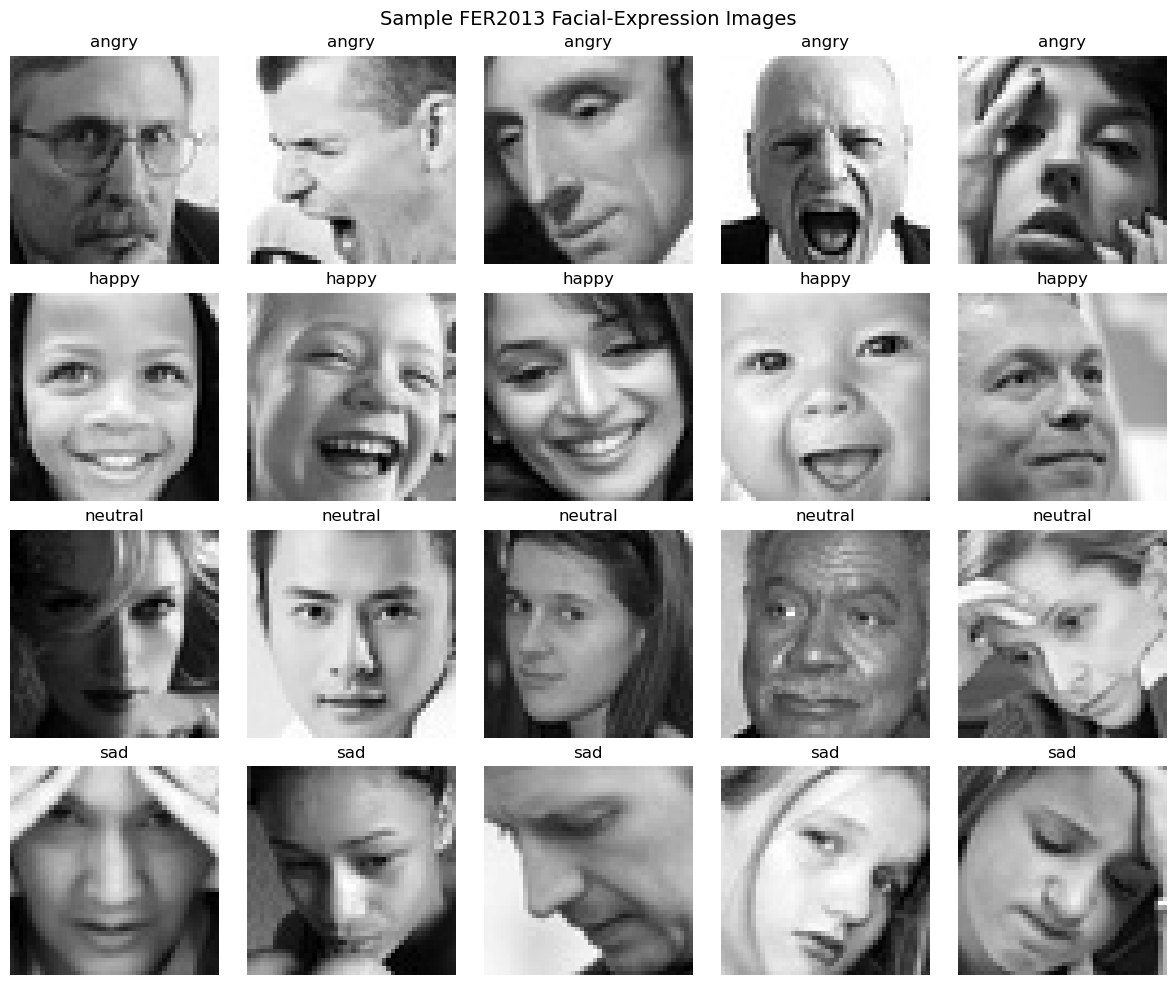


Calculating average image for: angry
Images used: 234

Calculating average image for: happy
Images used: 460

Calculating average image for: neutral
Images used: 291

Calculating average image for: sad
Images used: 317


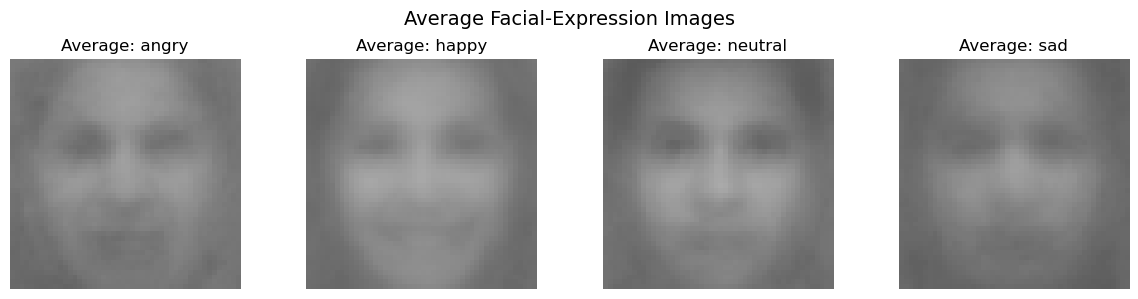


Cosine similarity between average expression images:
Category 1 Category 2  Cosine Similarity
     angry        sad           0.998915
     happy        sad           0.998757
     happy    neutral           0.998391
   neutral        sad           0.998201
     angry      happy           0.997866
     angry    neutral           0.996834


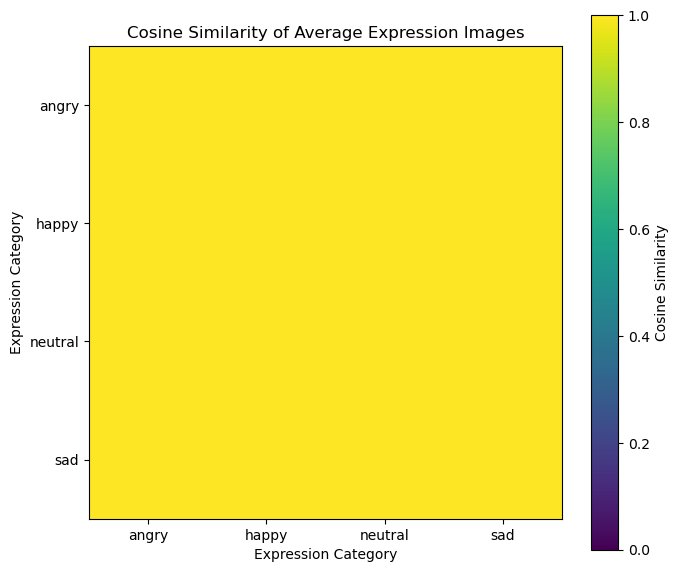


EXPLORATION SUMMARY
Total cleaned images: 25512
Images used for image exploration: 1302
Percentage sampled: 5.10%
Class imbalance ratio: 1.86
Dark images: 100 (7.68%)
Bright images: 9 (0.69%)

Most visually similar expression pair:
angry + sad = 0.9989

Data exploration completed successfully.

Cached exploration data released.


In [6]:

# ============================================================
# DATA EXPLORATIONS - FER2013
# Purpose: Explore the cleaned FER2013 dataset before CNN
# modelling using PySpark and Python visualisation tools.
#
# Image-level exploration uses a random 5% sample to reduce
# computational workload.
# ============================================================


# ------------------------------------------------------------
# REQUIRED IMPORTS
# ------------------------------------------------------------

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    DoubleType
)

from PIL import Image
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity


# ============================================================
# 1. DATA EXPLORATION
# ============================================================

print("========================================")
print("DATA EXPLORATION - FER2013")
print("========================================")


# ------------------------------------------------------------
# 2. CONFIRM CLEAN DATASET
# Purpose: Confirm that exploration uses the cleaned dataset.
# ------------------------------------------------------------

total_records = df_clean.count()

print(f"\nTotal cleaned records: {total_records}")


# ------------------------------------------------------------
# 3. CLASS DISTRIBUTION
# Purpose: Calculate the number and percentage of images
# in each selected facial-expression category.
#
# Uses the FULL cleaned dataset.
# ------------------------------------------------------------

class_distribution = (
    df_clean
    .groupBy("label")
    .count()
    .withColumn(
        "percentage",
        F.round(
            (F.col("count") / F.lit(total_records)) * 100,
            2
        )
    )
    .orderBy("label")
)

print("\nClass distribution:")

class_distribution.show(truncate=False)


# ------------------------------------------------------------
# 4. CALCULATE CLASS IMBALANCE RATIO
# Purpose: Compare the largest and smallest class.
#
# Uses the FULL cleaned dataset.
# ------------------------------------------------------------

class_counts = (
    df_clean
    .groupBy("label")
    .count()
)

largest_class = class_counts.agg(
    F.max("count")
).collect()[0][0]

smallest_class = class_counts.agg(
    F.min("count")
).collect()[0][0]

imbalance_ratio = largest_class / smallest_class

print(f"\nLargest class count: {largest_class}")
print(f"Smallest class count: {smallest_class}")
print(f"Class imbalance ratio: {imbalance_ratio:.2f}")


# ------------------------------------------------------------
# 5. CREATE RANDOM SAMPLE OF 5% OF IMAGES
# Purpose: Reduce computational workload during image-level
# exploration while preserving the full cleaned dataset.
#
# The original df_clean remains unchanged.
# ------------------------------------------------------------

exploration_sample = (
    df_clean
    .sample(
        withReplacement=False,
        fraction=0.05,
        seed=42
    )
    .cache()
)

sample_records = exploration_sample.count()

print("\nImage exploration sample:")
print(f"Total cleaned images: {total_records}")
print(f"Images selected: {sample_records}")
print(
    f"Percentage sampled: "
    f"{(sample_records / total_records) * 100:.2f}%"
)


# ------------------------------------------------------------
# 6. IMAGE DIMENSION AND STRUCTURE ANALYSIS
# Purpose: Examine image dimensions and grayscale information
# within the selected sample.
# ------------------------------------------------------------

dimension_summary = exploration_sample.select(
    F.min("width").alias("min_width"),
    F.max("width").alias("max_width"),
    F.round(F.avg("width"), 2).alias("avg_width"),
    F.min("height").alias("min_height"),
    F.max("height").alias("max_height"),
    F.round(F.avg("height"), 2).alias("avg_height")
)

print("\nDimension summary:")

dimension_summary.show()

print("\nGrayscale distribution:")

exploration_sample.groupBy(
    "grayscale"
).count().show()


# ------------------------------------------------------------
# 7. IMAGE PIXEL STATISTICS FUNCTION
# Purpose: Decode images and calculate mean pixel intensity
# and pixel-intensity standard deviation.
#
# Pixel values are normalized from 0-255 to 0-1.
# ------------------------------------------------------------

def calculate_pixel_statistics(content):

    try:

        image = Image.open(
            BytesIO(content)
        ).convert("L")

        pixels = np.asarray(
            image,
            dtype=np.float32
        )

        normalized_pixels = pixels / 255.0

        mean_intensity = float(
            normalized_pixels.mean()
        )

        std_intensity = float(
            normalized_pixels.std()
        )

        return (
            mean_intensity,
            std_intensity
        )

    except Exception:

        return (
            None,
            None
        )


# Define output structure for Spark UDF

pixel_statistics_schema = StructType([
    StructField(
        "mean_intensity",
        DoubleType(),
        True
    ),
    StructField(
        "std_intensity",
        DoubleType(),
        True
    )
])


# Create Spark UDF

pixel_statistics_udf = F.udf(
    calculate_pixel_statistics,
    pixel_statistics_schema
)


# ------------------------------------------------------------
# 8. CALCULATE PIXEL INTENSITY STATISTICS
# Purpose: Calculate mean and standard deviation of
# normalized pixel intensity for the 5% sample.
# ------------------------------------------------------------

exploration_df = (
    exploration_sample
    .withColumn(
        "pixel_statistics",
        pixel_statistics_udf(F.col("content"))
    )
    .withColumn(
        "mean_intensity",
        F.col("pixel_statistics.mean_intensity")
    )
    .withColumn(
        "std_intensity",
        F.col("pixel_statistics.std_intensity")
    )
    .drop("pixel_statistics")
    .cache()
)

print("\nPixel intensity statistics:")

exploration_df.select(
    F.round(
        F.min("mean_intensity"), 4
    ).alias("minimum_mean_intensity"),

    F.round(
        F.max("mean_intensity"), 4
    ).alias("maximum_mean_intensity"),

    F.round(
        F.avg("mean_intensity"), 4
    ).alias("overall_mean_intensity"),

    F.round(
        F.stddev("mean_intensity"), 4
    ).alias("std_of_image_mean_intensity")

).show()


# ------------------------------------------------------------
# 9. PIXEL INTENSITY STANDARD DEVIATION
# Purpose: Examine variation in pixel intensity within
# individual images.
# ------------------------------------------------------------

print("\nPixel intensity standard deviation:")

exploration_df.select(
    F.round(
        F.avg("std_intensity"), 4
    ).alias("average_pixel_intensity_std"),

    F.round(
        F.min("std_intensity"), 4
    ).alias("minimum_pixel_intensity_std"),

    F.round(
        F.max("std_intensity"), 4
    ).alias("maximum_pixel_intensity_std")

).show()


# ------------------------------------------------------------
# 10. BRIGHTNESS ANALYSIS
# Purpose: Identify unusually dark and bright images.
#
# Dark images: mean intensity < 0.30
# Bright images: mean intensity > 0.80
# ------------------------------------------------------------

dark_threshold = 0.30
bright_threshold = 0.80

dark_images = exploration_df.filter(
    F.col("mean_intensity") < dark_threshold
)

bright_images = exploration_df.filter(
    F.col("mean_intensity") > bright_threshold
)

dark_count = dark_images.count()
bright_count = bright_images.count()

dark_percentage = (
    dark_count / sample_records
) * 100

bright_percentage = (
    bright_count / sample_records
) * 100

print("\nBrightness analysis:")

print(
    f"Dark images (< {dark_threshold}): "
    f"{dark_count} ({dark_percentage:.2f}%)"
)

print(
    f"Bright images (> {bright_threshold}): "
    f"{bright_count} ({bright_percentage:.2f}%)"
)


# ------------------------------------------------------------
# 11. BRIGHTNESS BY EXPRESSION CATEGORY
# Purpose: Examine whether brightness differs between
# the four facial-expression categories.
# ------------------------------------------------------------

brightness_by_class = (
    exploration_df
    .groupBy("label")
    .agg(
        F.round(
            F.avg("mean_intensity"), 4
        ).alias("average_brightness"),

        F.round(
            F.stddev("mean_intensity"), 4
        ).alias("brightness_std")
    )
    .orderBy("label")
)

print("\nBrightness by expression category:")

brightness_by_class.show(truncate=False)


# ------------------------------------------------------------
# 12. VISUALISE CLASS DISTRIBUTION
# Purpose: Display class distribution using the full
# cleaned dataset.
# ------------------------------------------------------------

class_pd = class_distribution.toPandas()

plt.figure(figsize=(8, 5))

plt.bar(
    class_pd["label"],
    class_pd["count"],
    color="steelblue"
)

plt.xlabel("Facial Expression")
plt.ylabel("Number of Images")
plt.title("FER2013 Class Distribution")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. VISUALISE BRIGHTNESS DISTRIBUTION
# Purpose: Examine image brightness across the four
# expression categories using the 5% sample.
# ------------------------------------------------------------

brightness_pd = (
    exploration_df
    .select("label", "mean_intensity")
    .dropna()
    .toPandas()
)

plt.figure(figsize=(9, 5))

for label in [
    "angry",
    "happy",
    "neutral",
    "sad"
]:

    values = brightness_pd.loc[
        brightness_pd["label"] == label,
        "mean_intensity"
    ]

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=label
    )

plt.xlabel("Mean Normalised Pixel Intensity")
plt.ylabel("Number of Images")
plt.title("Distribution of Image Brightness")
plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. DISPLAY SAMPLE IMAGES
# Purpose: Display five representative images per category
# from the 5% exploration sample.
# ------------------------------------------------------------

sample_images = []

for label in [
    "angry",
    "happy",
    "neutral",
    "sad"
]:

    sample = (
        exploration_sample
        .filter(F.col("label") == label)
        .orderBy(F.rand(seed=42))
        .limit(5)
        .select("label", "content")
        .collect()
    )

    for row in sample:

        image = Image.open(
            BytesIO(row["content"])
        ).convert("L")

        sample_images.append(
            (label, image)
        )


# Display images

fig, axes = plt.subplots(
    4,
    5,
    figsize=(12, 10)
)

for ax in axes.flat:
    ax.axis("off")

for index, (label, image) in enumerate(sample_images):

    axes[index // 5][index % 5].imshow(
        image,
        cmap="gray"
    )

    axes[index // 5][index % 5].set_title(label)

    axes[index // 5][index % 5].axis("off")

plt.suptitle(
    "Sample FER2013 Facial-Expression Images",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. CREATE AVERAGE IMAGE FOR EACH CATEGORY
# Purpose: Calculate representative average facial-image
# patterns using the 5% exploration sample.
# ------------------------------------------------------------

average_images = {}

for label in [
    "angry",
    "happy",
    "neutral",
    "sad"
]:

    print(
        f"\nCalculating average image for: {label}"
    )

    rows = (
        exploration_sample
        .filter(F.col("label") == label)
        .select("content")
        .toLocalIterator()
    )

    pixel_sum = None
    image_count = 0

    for row in rows:

        image = Image.open(
            BytesIO(row["content"])
        ).convert("L")

        pixels = np.asarray(
            image,
            dtype=np.float64
        )

        if pixel_sum is None:

            pixel_sum = np.zeros_like(
                pixels,
                dtype=np.float64
            )

        pixel_sum += pixels
        image_count += 1

    if image_count == 0:

        raise ValueError(
            f"No sampled images found for category: {label}"
        )

    average_image = pixel_sum / image_count

    average_images[label] = (
        average_image / 255.0
    )

    print(f"Images used: {image_count}")


# ------------------------------------------------------------
# 16. DISPLAY AVERAGE IMAGES
# Purpose: Compare average visual patterns of the four
# facial-expression categories.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    4,
    figsize=(12, 3)
)

for index, label in enumerate([
    "angry",
    "happy",
    "neutral",
    "sad"
]):

    axes[index].imshow(
        average_images[label],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[index].set_title(
        f"Average: {label}"
    )

    axes[index].axis("off")

plt.suptitle(
    "Average Facial-Expression Images",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 17. CALCULATE COSINE SIMILARITY
# Purpose: Compare pixel patterns of the average images
# and identify the most visually similar categories.
# ------------------------------------------------------------

labels = [
    "angry",
    "happy",
    "neutral",
    "sad"
]

average_vectors = np.array([
    average_images[label].flatten()
    for label in labels
])

similarity_matrix = cosine_similarity(
    average_vectors
)

similarity_results = []

for i in range(len(labels)):

    for j in range(i + 1, len(labels)):

        similarity_results.append({
            "Category 1": labels[i],
            "Category 2": labels[j],
            "Cosine Similarity": similarity_matrix[i, j]
        })


similarity_df = pd.DataFrame(
    similarity_results
)

similarity_df = similarity_df.sort_values(
    by="Cosine Similarity",
    ascending=False
)

print("\nCosine similarity between average expression images:")

print(
    similarity_df.to_string(index=False)
)


# ------------------------------------------------------------
# 18. VISUALISE COSINE SIMILARITY MATRIX
# Purpose: Visual comparison of similarity between
# average facial-expression patterns.
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.imshow(
    similarity_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.xticks(
    range(len(labels)),
    labels
)

plt.yticks(
    range(len(labels)),
    labels
)

plt.xlabel("Expression Category")
plt.ylabel("Expression Category")

plt.title(
    "Cosine Similarity of Average Expression Images"
)

plt.colorbar(
    label="Cosine Similarity"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 19. FINAL EXPLORATION SUMMARY
# Purpose: Print the main numerical findings for the report.
# ------------------------------------------------------------

print("\n========================================")
print("EXPLORATION SUMMARY")
print("========================================")

print(
    f"Total cleaned images: {total_records}"
)

print(
    f"Images used for image exploration: {sample_records}"
)

print(
    f"Percentage sampled: "
    f"{(sample_records / total_records) * 100:.2f}%"
)

print(
    f"Class imbalance ratio: {imbalance_ratio:.2f}"
)

print(
    f"Dark images: "
    f"{dark_count} ({dark_percentage:.2f}%)"
)

print(
    f"Bright images: "
    f"{bright_count} ({bright_percentage:.2f}%)"
)

print("\nMost visually similar expression pair:")

most_similar = similarity_df.iloc[0]

print(
    f"{most_similar['Category 1']} + "
    f"{most_similar['Category 2']} = "
    f"{most_similar['Cosine Similarity']:.4f}"
)

print(
    "\nData exploration completed successfully."
)


# ------------------------------------------------------------
# 20. RELEASE CACHED DATA
# Purpose: Release cached Spark DataFrames after exploration.
# ------------------------------------------------------------

exploration_df.unpersist()
exploration_sample.unpersist()

print("\nCached exploration data released.")


## 3. Data Visualization 
**The Plan**

The visualisation activities include:
- Creating bar charts to compare the number of images across the four facial-expression categories;
- Displaying a grid of sample facial images from each category;
- Plotting pixel-intensity histograms to examine the distribution of grayscale values;
- Creating boxplots to compare image brightness across expression categories; and
- Visualising selected CNN feature maps to illustrate patterns learned during model training.



DATA VISUALIZATION - FER2013

Total cleaned images: 25512
Images in exploration sample: 1302
Percentage sampled: 5.10%


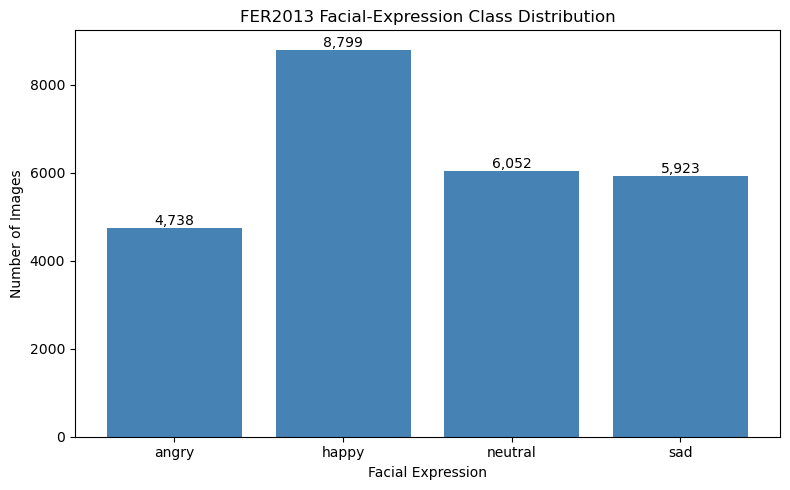

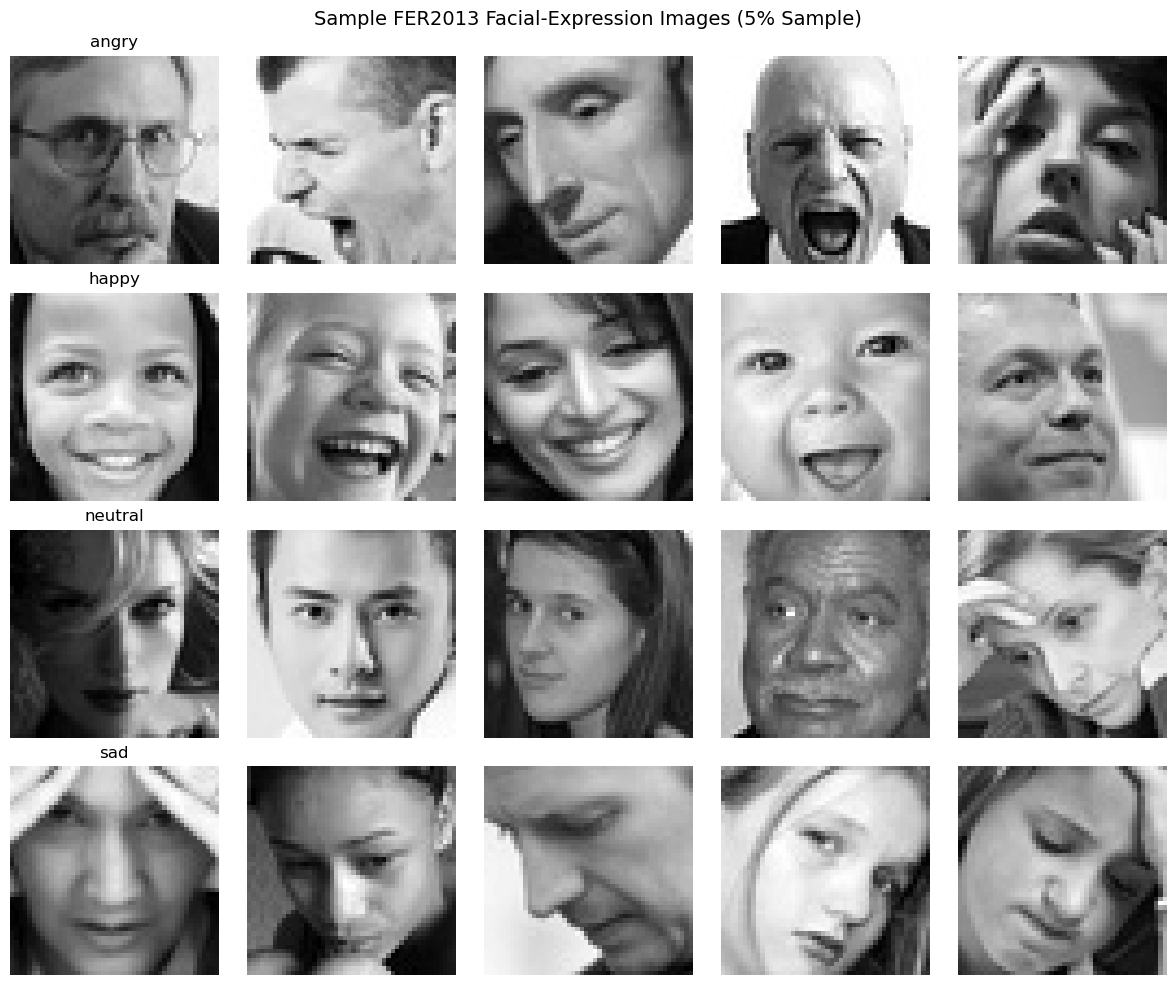

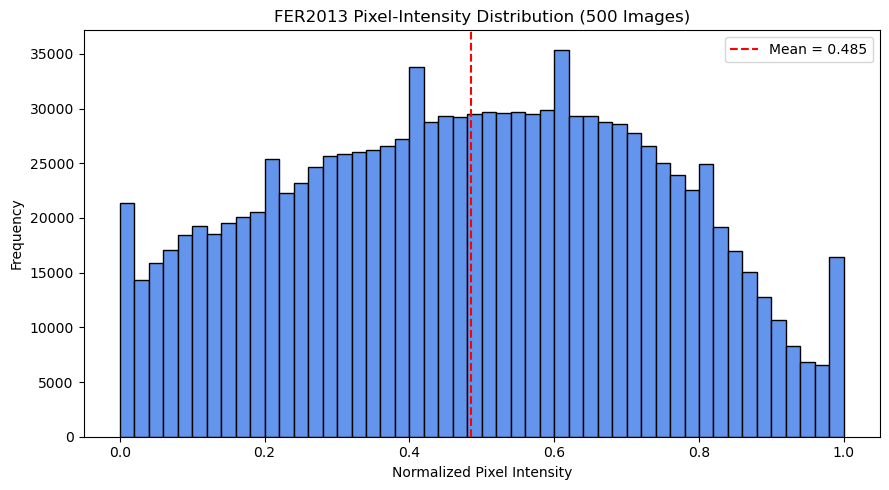


Pixel intensity results:
Images used: 500
Sample pixel-intensity mean: 0.4849
Sample pixel-intensity standard deviation: 0.2522


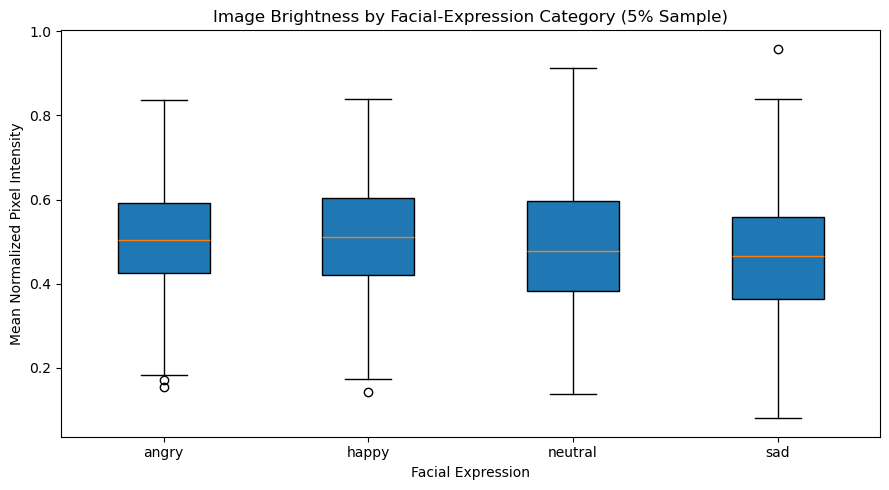


Brightness boxplot data:
         count    mean     std     min     25%     50%     75%     max
label                                                                 
angry    234.0  0.4995  0.1276  0.1535  0.4255  0.5043  0.5909  0.8371
happy    460.0  0.5128  0.1254  0.1422  0.4205  0.5110  0.6032  0.8377
neutral  291.0  0.4889  0.1379  0.1375  0.3836  0.4774  0.5967  0.9134
sad      317.0  0.4658  0.1372  0.0804  0.3644  0.4663  0.5593  0.9580

DATA VISUALIZATION SUMMARY
Total cleaned images: 25512
Exploration sample: 1302
Sample percentage: 5.10%
Images used for pixel histogram: 500
Pixel intensity mean: 0.4849
Pixel intensity standard deviation: 0.2522

Visualisation activities completed:
1. Facial-expression class distribution
2. Sample facial-image grid
3. Pixel-intensity histogram
4. Image brightness boxplot

CNN feature-map visualisation will be performed
after CNN model training.

Data visualization completed successfully.


In [8]:

# ============================================================
# DATA VISUALIZATION - FER2013
# Purpose: Visualise dataset characteristics using
# Matplotlib and the results of PySpark data exploration.
#
# Image-level visualisations use the existing 5% sample.
# The full cleaned dataset is only used for class counts.
# CNN feature maps will be performed after model training.
# ============================================================


# ------------------------------------------------------------
# 0. CONFIRM VISUALISATION SAMPLE
# Purpose: Reuse the 5% sample created during data exploration
# rather than processing the entire cleaned dataset again.
# ------------------------------------------------------------

print("========================================")
print("DATA VISUALIZATION - FER2013")
print("========================================")

print(f"\nTotal cleaned images: {total_records}")
print(f"Images in exploration sample: {sample_records}")

print(
    f"Percentage sampled: "
    f"{(sample_records / total_records) * 100:.2f}%"
)

# Reuse the existing 5% exploration sample
visualization_sample = exploration_sample


# ------------------------------------------------------------
# 1. FACIAL-EXPRESSION CLASS DISTRIBUTION
# Purpose: Display the number of images in each expression
# category using the full cleaned dataset.
# ------------------------------------------------------------

# Reuse class distribution calculated during exploration
class_pd = class_distribution.toPandas()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_pd["label"],
    class_pd["count"],
    color="steelblue"
)

# Display count above each bar
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Facial Expression")
plt.ylabel("Number of Images")

plt.title(
    "FER2013 Facial-Expression Class Distribution"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. SAMPLE FACIAL-IMAGE GRID
# Purpose: Display five randomly selected images from each
# expression category using the 5% exploration sample.
# ------------------------------------------------------------

labels = [
    "angry",
    "happy",
    "neutral",
    "sad"
]

fig, axes = plt.subplots(
    4,
    5,
    figsize=(12, 10)
)

for row, label in enumerate(labels):

    # Select five reproducible images from the 5% sample
    samples = (
        visualization_sample
        .filter(F.col("label") == label)
        .orderBy(F.rand(seed=42))
        .limit(5)
        .select("content")
        .collect()
    )

    for column, sample in enumerate(samples):

        image = Image.open(
            BytesIO(sample["content"])
        ).convert("L")

        axes[row, column].imshow(
            image,
            cmap="gray"
        )

        axes[row, column].set_title(
            label if column == 0 else ""
        )

        axes[row, column].axis("off")

plt.suptitle(
    "Sample FER2013 Facial-Expression Images (5% Sample)",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. PIXEL-INTENSITY HISTOGRAM
# Purpose: Display the distribution of normalized grayscale
# pixel values using 500 images selected from the 5% sample.
#
# Pixel values range from 0 (black) to 1 (white).
# ------------------------------------------------------------

# Select 500 reproducible images from the 5% sample
pixel_samples = (
    visualization_sample
    .orderBy(F.rand(seed=42))
    .limit(500)
    .select("content")
    .collect()
)

pixel_values = []

for sample in pixel_samples:

    image = Image.open(
        BytesIO(sample["content"])
    ).convert("L")

    pixels = np.asarray(
        image,
        dtype=np.float32
    )

    # Normalize pixel values to 0-1
    normalized_pixels = pixels / 255.0

    pixel_values.extend(
        normalized_pixels.flatten()
    )

pixel_values = np.asarray(
    pixel_values,
    dtype=np.float32
)

pixel_mean = pixel_values.mean()
pixel_std = pixel_values.std()

plt.figure(figsize=(9, 5))

plt.hist(
    pixel_values,
    bins=50,
    edgecolor="black",
    color="cornflowerblue"
)

plt.axvline(
    pixel_mean,
    color="red",
    linestyle="--",
    label=f"Mean = {pixel_mean:.3f}"
)

plt.xlabel("Normalized Pixel Intensity")
plt.ylabel("Frequency")

plt.title(
    "FER2013 Pixel-Intensity Distribution (500 Images)"
)

plt.legend()

plt.tight_layout()
plt.show()

print("\nPixel intensity results:")

print(
    f"Images used: {len(pixel_samples)}"
)

print(
    f"Sample pixel-intensity mean: {pixel_mean:.4f}"
)

print(
    f"Sample pixel-intensity standard deviation: "
    f"{pixel_std:.4f}"
)


# ------------------------------------------------------------
# 4. IMAGE BRIGHTNESS BOXPLOT
# Purpose: Compare average image brightness across the four
# expression categories using the existing 5% sample results.
# ------------------------------------------------------------

# Reuse brightness statistics from data exploration
brightness_pd = (
    exploration_df
    .select(
        "label",
        "mean_intensity"
    )
    .toPandas()
)

plt.figure(figsize=(9, 5))

brightness_data = [
    brightness_pd.loc[
        brightness_pd["label"] == label,
        "mean_intensity"
    ].dropna().values

    for label in labels
]

plt.boxplot(
    brightness_data,
    tick_labels=labels,
    patch_artist=True
)

plt.xlabel("Facial Expression")
plt.ylabel("Mean Normalized Pixel Intensity")

plt.title(
    "Image Brightness by Facial-Expression Category (5% Sample)"
)

plt.tight_layout()
plt.show()

print("\nBrightness boxplot data:")

print(
    brightness_pd.groupby("label")["mean_intensity"]
    .describe()
    .round(4)
)


# ------------------------------------------------------------
# 5. FINAL DATA VISUALIZATION SUMMARY
# Purpose: Summarise the visualisation activities performed.
# ------------------------------------------------------------

print("\n========================================")
print("DATA VISUALIZATION SUMMARY")
print("========================================")

print(
    f"Total cleaned images: {total_records}"
)

print(
    f"Exploration sample: {sample_records}"
)

print(
    f"Sample percentage: "
    f"{(sample_records / total_records) * 100:.2f}%"
)

print(
    f"Images used for pixel histogram: "
    f"{len(pixel_samples)}"
)

print(
    f"Pixel intensity mean: {pixel_mean:.4f}"
)

print(
    f"Pixel intensity standard deviation: "
    f"{pixel_std:.4f}"
)

print("\nVisualisation activities completed:")
print("1. Facial-expression class distribution")
print("2. Sample facial-image grid")
print("3. Pixel-intensity histogram")
print("4. Image brightness boxplot")

print("\nCNN feature-map visualisation will be performed")
print("after CNN model training.")

print("\nData visualization completed successfully.")


## 4. Data Transformation 
**4.1 Feature Engineering**

**The Plan**


The purpose of feature engineering is to transform the cleaned FER2013 images into a consistent numerical format suitable for CNN modelling.

The process includes pixel normalisation, label encoding, preparation of training, validation and test datasets, and data augmentation.

These transformations aim to improve model training, maintain data consistency and reduce overfitting.



DATA TRANSFORMATION - FER2013
4.1 FEATURE ENGINEERING

Total cleaned images: 25512
Images selected: 1302
Percentage sampled: 5.10%

Preparing image tensors...

Image tensor preparation completed.
Image tensor shape: (1302, 48, 48, 1)
Label array shape: (1302,)
Image data type: float32
Label data type: int32
Minimum pixel value: 0.0000
Maximum pixel value: 1.0000

Label encoding:
angry: 0
happy: 1
neutral: 2
sad: 3

Number of expression categories: 4
Output activation: Softmax
Loss function: Sparse categorical cross-entropy

Creating stratified dataset partitions...

Dataset partition results:
   Dataset  Images Percentage
  Training     910     69.89%
Validation     196     15.05%
   Testing     196     15.05%

Total partitioned images: 1302

Class distribution across dataset partitions:

Training:
angry: 164 (18.02%)
happy: 322 (35.38%)
neutral: 203 (22.31%)
sad: 221 (24.29%)

Validation:
angry: 35 (17.86%)
happy: 69 (35.20%)
neutral: 44 (22.45%)
sad: 48 (24.49%)

Testing:
angry: 35 (

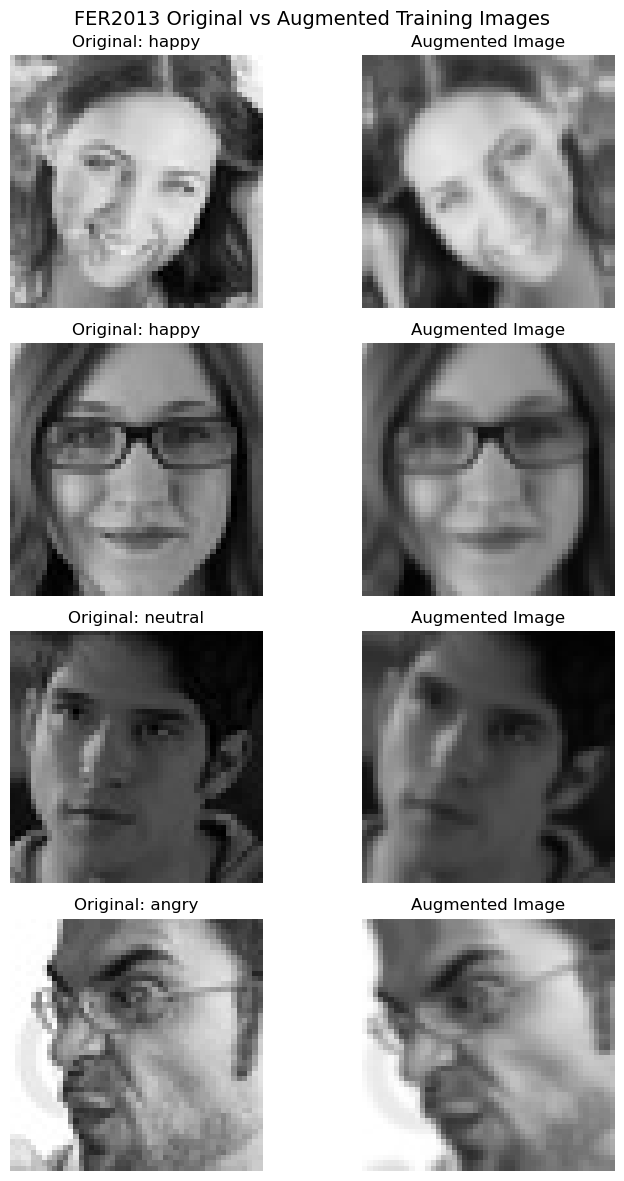


FEATURE ENGINEERING SUMMARY
Original cleaned dataset: 25512
Images used (5% sample): 1302
Input image shape: (48, 48, 1)
Pixel intensity range: 0.0 - 1.0
Number of expression categories: 4
Training images: 910
Validation images: 196
Testing images: 196

Pixel normalisation: Completed
Image tensor preparation: Completed
Integer label encoding: Completed
Stratified dataset splitting: Completed
Data augmentation configuration: Completed

Feature engineering completed successfully.


In [9]:

# ============================================================
# DATA TRANSFORMATION - FER2013
# 4.1 FEATURE ENGINEERING
#
# Purpose: Transform the cleaned FER2013 images into
# numerical tensors suitable for CNN modelling.
#
# Image-level processing uses the existing 5% sample.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split


# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)


# ------------------------------------------------------------
# 1. CONFIRM FEATURE ENGINEERING DATASET
# Purpose: Reuse the existing 5% exploration sample rather
# than processing the entire cleaned dataset again.
# ------------------------------------------------------------

print("========================================")
print("DATA TRANSFORMATION - FER2013")
print("4.1 FEATURE ENGINEERING")
print("========================================")

feature_sample = exploration_sample

feature_records = feature_sample.count()

print(f"\nTotal cleaned images: {total_records}")
print(f"Images selected: {feature_records}")

print(
    f"Percentage sampled: "
    f"{(feature_records / total_records) * 100:.2f}%"
)


# ------------------------------------------------------------
# 2. PIXEL SCALING AND IMAGE TENSOR PREPARATION
# Purpose:
# - Decode the grayscale images.
# - Preserve their 48 x 48 dimensions.
# - Convert pixel values from 0-255 to 0-1.
# - Add a single channel dimension for CNN input.
# ------------------------------------------------------------

print("\nPreparing image tensors...")

# Collect image content and associated labels
feature_rows = (
    feature_sample
    .select("label", "content")
    .collect()
)

# Define the numerical representation of each expression
label_mapping = {
    "angry": 0,
    "happy": 1,
    "neutral": 2,
    "sad": 3
}

# Store images and labels
image_data = []
label_data = []

for row in feature_rows:

    # Decode image as grayscale
    image = Image.open(
        BytesIO(row["content"])
    ).convert("L")

    # Convert image to numerical array
    pixels = np.asarray(
        image,
        dtype=np.float32
    )

    # Normalize pixel values to 0-1
    normalized_pixels = pixels / 255.0

    # Add image and corresponding numerical label
    image_data.append(normalized_pixels)

    label_data.append(
        label_mapping[row["label"]]
    )


# Convert image and label collections into NumPy arrays
X = np.asarray(
    image_data,
    dtype=np.float32
)

y = np.asarray(
    label_data,
    dtype=np.int32
)

# Add grayscale channel dimension
X = np.expand_dims(
    X,
    axis=-1
)

print("\nImage tensor preparation completed.")

print(f"Image tensor shape: {X.shape}")
print(f"Label array shape: {y.shape}")
print(f"Image data type: {X.dtype}")
print(f"Label data type: {y.dtype}")

print(
    f"Minimum pixel value: {X.min():.4f}"
)

print(
    f"Maximum pixel value: {X.max():.4f}"
)


# ------------------------------------------------------------
# 3. LABEL ENCODING
# Purpose: Represent the four facial-expression categories
# using integer values suitable for sparse categorical
# cross-entropy during CNN training.
# ------------------------------------------------------------

print("\nLabel encoding:")

for label, encoded_value in label_mapping.items():

    print(
        f"{label}: {encoded_value}"
    )

number_of_classes = len(label_mapping)

print(
    f"\nNumber of expression categories: "
    f"{number_of_classes}"
)

print(
    "Output activation: Softmax"
)

print(
    "Loss function: Sparse categorical cross-entropy"
)


# ------------------------------------------------------------
# 4. STRATIFIED TRAINING, VALIDATION AND TEST SPLIT
# Purpose:
# - Allocate 70% for training.
# - Allocate 15% for validation.
# - Allocate 15% for final testing.
# - Preserve the proportions of expression categories.
#
# The test set remains separate from model development.
# ------------------------------------------------------------

print("\nCreating stratified dataset partitions...")

# First, separate 15% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(

    X,
    y,

    test_size=0.15,

    random_state=42,

    stratify=y
)


# Separate 15% of the original dataset for validation.
# Since 15% has already been allocated to testing,
# validation represents 15/85 of the remaining data.

validation_fraction = 0.15 / 0.85

X_train, X_val, y_train, y_val = train_test_split(

    X_train_val,
    y_train_val,

    test_size=validation_fraction,

    random_state=42,

    stratify=y_train_val
)


# ------------------------------------------------------------
# 5. REPORT DATASET PARTITION SIZES
# Purpose: Confirm the number and percentage of images
# allocated to each dataset partition.
# ------------------------------------------------------------

split_results = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],

    "Images": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],

    "Percentage": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]

})

print("\nDataset partition results:")

print(
    split_results.to_string(
        index=False,
        formatters={
            "Percentage": lambda value: f"{value:.2f}%"
        }
    )
)

print(
    f"\nTotal partitioned images: "
    f"{len(X_train) + len(X_val) + len(X_test)}"
)


# ------------------------------------------------------------
# 6. VERIFY CLASS DISTRIBUTION AFTER SPLITTING
# Purpose: Confirm that stratified sampling has maintained
# the distribution of facial-expression categories.
# ------------------------------------------------------------

print("\nClass distribution across dataset partitions:")

partition_names = [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]

for partition_name, partition_labels in partition_names:

    print(f"\n{partition_name}:")

    unique_labels, counts = np.unique(
        partition_labels,
        return_counts=True
    )

    for encoded_label, count in zip(
        unique_labels,
        counts
    ):

        expression = list(label_mapping.keys())[
            list(label_mapping.values()).index(encoded_label)
        ]

        percentage = (
            count / len(partition_labels)
        ) * 100

        print(
            f"{expression}: {count} ({percentage:.2f}%)"
        )


# ------------------------------------------------------------
# 7. DEFINE DATA AUGMENTATION
# Purpose: Introduce small random transformations to
# training images to increase visual diversity.
#
# Transformations:
# - Random horizontal flipping.
# - Small random rotations.
# - Small random zoom transformations.
#
# Augmentation is applied during model training only.
# Validation and test images remain unchanged.
# ------------------------------------------------------------

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        factor=0.05
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    )

], name="FER2013_Data_Augmentation")


print("\nData augmentation configuration:")

print("Random horizontal flipping: Enabled")
print("Random rotation: Enabled (0.05)")
print("Random zoom: Enabled (0.10)")


# ------------------------------------------------------------
# 8. VISUALISE AUGMENTED IMAGE EXAMPLES
# Purpose: Compare original training images with their
# randomly augmented versions.
#
# This demonstrates the transformations applied during
# training without permanently modifying the dataset.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    2,
    figsize=(8, 12)
)

for index in range(4):

    original_image = X_train[index]

    # Apply augmentation to one image
    augmented_image = data_augmentation(
        tf.expand_dims(
            original_image,
            axis=0
        ),
        training=True
    )[0].numpy()

    # Decode numerical label
    expression = list(label_mapping.keys())[
        list(label_mapping.values()).index(y_train[index])
    ]

    # Display original image
    axes[index, 0].imshow(
        original_image.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[index, 0].set_title(
        f"Original: {expression}"
    )

    axes[index, 0].axis("off")

    # Display augmented image
    axes[index, 1].imshow(
        augmented_image.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[index, 1].set_title(
        "Augmented Image"
    )

    axes[index, 1].axis("off")


plt.suptitle(
    "FER2013 Original vs Augmented Training Images",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. FINAL FEATURE ENGINEERING SUMMARY
# Purpose: Report the transformations completed and
# confirm that the datasets are ready for CNN modelling.
# ------------------------------------------------------------

print("\n========================================")
print("FEATURE ENGINEERING SUMMARY")
print("========================================")

print(
    f"Original cleaned dataset: {total_records}"
)

print(
    f"Images used (5% sample): {len(X)}"
)

print(
    f"Input image shape: {X.shape[1:]}"
)

print(
    f"Pixel intensity range: {X.min():.1f} - {X.max():.1f}"
)

print(
    f"Number of expression categories: {number_of_classes}"
)

print(
    f"Training images: {len(X_train)}"
)

print(
    f"Validation images: {len(X_val)}"
)

print(
    f"Testing images: {len(X_test)}"
)

print(
    "\nPixel normalisation: Completed"
)

print(
    "Image tensor preparation: Completed"
)

print(
    "Integer label encoding: Completed"
)

print(
    "Stratified dataset splitting: Completed"
)

print(
    "Data augmentation configuration: Completed"
)

print(
    "\nFeature engineering completed successfully."
)


## Model Training
1. Training approach

We will use the datasets already created in your feature engineering section:

    X_train, y_train: Training data.

    X_val, y_val: Validation data.

    X_test, y_test: Reserved for final evaluation. We will not use these during training.

In [10]:

# ============================================================
# 4.2 MODEL TRAINING - FER2013
# BASELINE CNN MODEL
#
# Uses the existing 5% dataset sample.
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("========================================")
print("4.2 MODEL TRAINING - BASELINE CNN")
print("========================================")

# ------------------------------------------------------------
# 1. CONFIRM TRAINING DATA
# ------------------------------------------------------------

print("\nConfirming existing 5% dataset sample...")

print(f"Training images: {len(X_train)}")
print(f"Validation images: {len(X_val)}")
print(f"Testing images (reserved): {len(X_test)}")

print(f"Input shape: {X_train.shape[1:]}")

# ------------------------------------------------------------
# 2. BUILD BASELINE CNN
# ------------------------------------------------------------

baseline_model = models.Sequential([

    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.25),

    layers.Dense(
        4,
        activation="softmax"
    )

], name="Baseline_CNN")


# ------------------------------------------------------------
# 3. COMPILE BASELINE CNN
# ------------------------------------------------------------

baseline_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("\nBaseline CNN model summary:")

baseline_model.summary()


# ------------------------------------------------------------
# 4. EARLY STOPPING
# ------------------------------------------------------------

baseline_early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1

)


# ------------------------------------------------------------
# 5. TRAIN BASELINE CNN
# ------------------------------------------------------------

print("\nStarting baseline CNN training...")

baseline_history = baseline_model.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,

    batch_size=64,

    callbacks=[
        baseline_early_stopping
    ],

    verbose=1

)

print("\nBaseline CNN training completed.")


4.2 MODEL TRAINING - BASELINE CNN

Confirming existing 5% dataset sample...
Training images: 910
Validation images: 196
Testing images (reserved): 196
Input shape: (48, 48, 1)

Baseline CNN model summary:


Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,700 (428.52 KB)

 Trainable params: 109,700 (428.52 KB)

 Non-trainable params: 0 (0.00 B)


Starting baseline CNN training...
Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.3407 - loss: 1.3656 - val_accuracy: 0.3520 - val_loss: 1.3671
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.3516 - loss: 1.3661 - val_accuracy: 0.3520 - val_loss: 1.3602
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.3538 - loss: 1.3530 - val_accuracy: 0.3520 - val_loss: 1.3586
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.3538 - loss: 1.3590 - val_accuracy: 0.3520 - val_loss: 1.3558
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.3538 - loss: 1.3553 - val_accuracy: 0.3520 - val_loss: 1.3554
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.3549 - loss: 1.3548 - val_accuracy: 0.3520 - val_loss: 1.3546
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.3593 - loss: 1.3547 - val_accuracy: 0.3520 - val_loss: 1.3532
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.3703 - loss

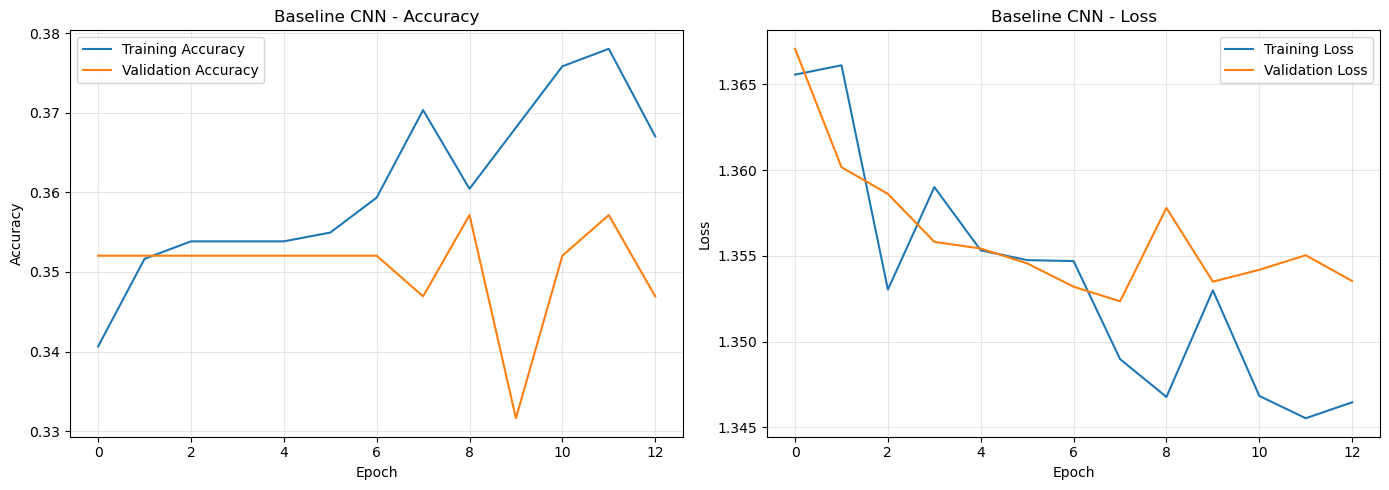


BASELINE CNN TRAINING RESULTS
Epochs completed: 13
Best epoch: 8
Training accuracy at best epoch: 0.3703
Validation accuracy at best epoch: 0.3469
Best validation loss: 1.3524
Trainable parameters: 109,700


In [11]:

# ============================================================
# BASELINE CNN - TRAINING PERFORMANCE
# ============================================================

# Extract training history
baseline_accuracy = baseline_history.history["accuracy"]
baseline_val_accuracy = baseline_history.history["val_accuracy"]

baseline_loss = baseline_history.history["loss"]
baseline_val_loss = baseline_history.history["val_loss"]

# Identify best epoch using validation loss
baseline_best_epoch = (
    np.argmin(baseline_val_loss) + 1
)

# Retrieve metrics from best epoch
baseline_best_train_accuracy = (
    baseline_accuracy[baseline_best_epoch - 1]
)

baseline_best_val_accuracy = (
    baseline_val_accuracy[baseline_best_epoch - 1]
)

baseline_best_val_loss = (
    baseline_val_loss[baseline_best_epoch - 1]
)

# ------------------------------------------------------------
# PLOT ACCURACY AND LOSS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    baseline_accuracy,
    label="Training Accuracy"
)

axes[0].plot(
    baseline_val_accuracy,
    label="Validation Accuracy"
)

axes[0].set_title(
    "Baseline CNN - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    baseline_loss,
    label="Training Loss"
)

axes[1].plot(
    baseline_val_loss,
    label="Validation Loss"
)

axes[1].set_title(
    "Baseline CNN - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# REPORT BASELINE RESULTS
# ------------------------------------------------------------

print("\n========================================")
print("BASELINE CNN TRAINING RESULTS")
print("========================================")

print(
    f"Epochs completed: {len(baseline_accuracy)}"
)

print(
    f"Best epoch: {baseline_best_epoch}"
)

print(
    f"Training accuracy at best epoch: "
    f"{baseline_best_train_accuracy:.4f}"
)

print(
    f"Validation accuracy at best epoch: "
    f"{baseline_best_val_accuracy:.4f}"
)

print(
    f"Best validation loss: "
    f"{baseline_best_val_loss:.4f}"
)

print(
    f"Trainable parameters: "
    f"{baseline_model.count_params():,}"
)


In [12]:

# ============================================================
# IMPROVED CNN MODEL - FER2013
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

print("\n========================================")
print("IMPROVED CNN MODEL")
print("========================================")

# ------------------------------------------------------------
# 1. DEFINE DATA AUGMENTATION
# ------------------------------------------------------------

improved_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )

], name="Improved_Data_Augmentation")


# ------------------------------------------------------------
# 2. BUILD IMPROVED CNN
# ------------------------------------------------------------

improved_model = models.Sequential([

    layers.Input(shape=(48, 48, 1)),

    # Data augmentation
    improved_augmentation,

    # Convolutional feature extraction
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.30),

    layers.Dense(
        4,
        activation="softmax"
    )

], name="Improved_CNN")


# ------------------------------------------------------------
# 3. COMPILE IMPROVED CNN
# ------------------------------------------------------------

improved_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("\nImproved CNN model summary:")

improved_model.summary()


# ------------------------------------------------------------
# 4. DEFINE TRAINING CALLBACKS
# ------------------------------------------------------------

improved_early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1

)

reduce_learning_rate = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=2,

    min_lr=0.000001,

    verbose=1

)


# ------------------------------------------------------------
# 5. TRAIN IMPROVED CNN
# ------------------------------------------------------------

print("\nStarting improved CNN training...")

improved_history = improved_model.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,

    batch_size=64,

    callbacks=[
        reduce_learning_rate,
        improved_early_stopping
    ],

    verbose=1

)

print("\nImproved CNN training completed.")



IMPROVED CNN MODEL

Improved CNN model summary:


Model: "Improved_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Improved_Data_Augmentation      │ (None, 48, 48, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,700 (428.52 KB)

 Trainable params: 109,700 (428.52 KB)

 Non-trainable params: 0 (0.00 B)


Starting improved CNN training...
Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.3407 - loss: 1.3630 - val_accuracy: 0.3520 - val_loss: 1.3607 - learning_rate: 5.0000e-04
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.3538 - loss: 1.3592 - val_accuracy: 0.3520 - val_loss: 1.3572 - learning_rate: 5.0000e-04
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.3538 - loss: 1.3501 - val_accuracy: 0.3520 - val_loss: 1.3578 - learning_rate: 5.0000e-04
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.3538 - loss: 1.3546 - val_accuracy: 0.3520 - val_loss: 1.3565 - learning_rate: 5.0000e-04
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.3538 - loss: 1.3535 - val_accuracy: 0.3520 - val_loss: 1.3563 - learning_rate: 5.0000e-04
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.3538 - loss: 1.3557 - val_accuracy: 0.3520 - val_loss: 1.3556 - learning_rate: 5.0000e-04
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━

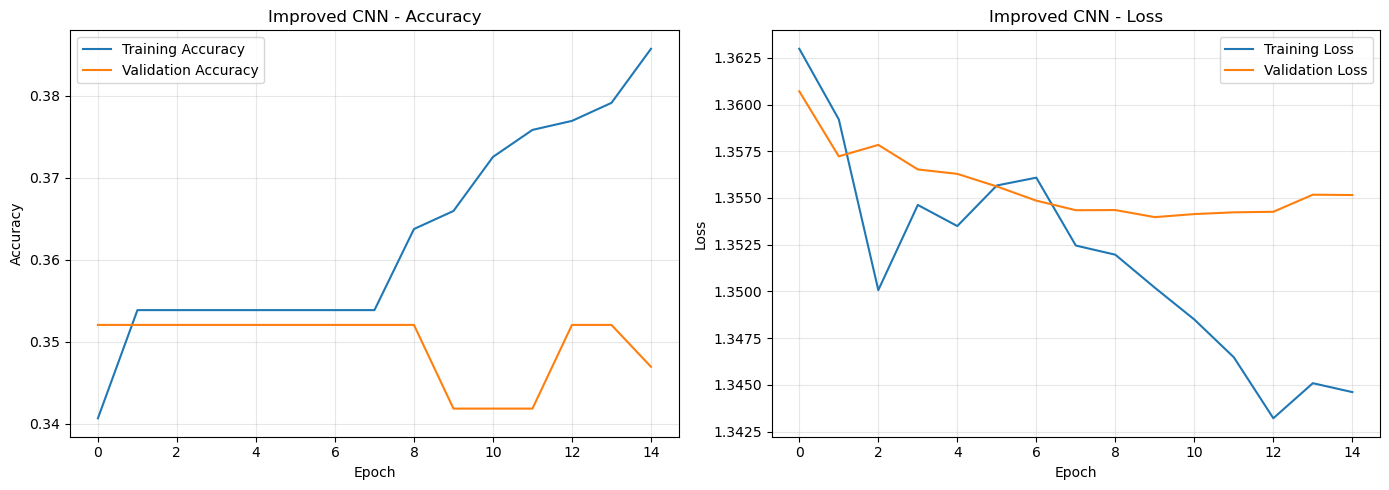


IMPROVED CNN TRAINING RESULTS
Epochs completed: 15
Best epoch: 10
Training accuracy at best epoch: 0.3659
Validation accuracy at best epoch: 0.3418
Best validation loss: 1.3540
Trainable parameters: 109,700


In [13]:

# ============================================================
# IMPROVED CNN - TRAINING PERFORMANCE
# ============================================================

improved_accuracy = improved_history.history["accuracy"]

improved_val_accuracy = (
    improved_history.history["val_accuracy"]
)

improved_loss = improved_history.history["loss"]

improved_val_loss = (
    improved_history.history["val_loss"]
)

# Identify best epoch using validation loss
improved_best_epoch = (
    np.argmin(improved_val_loss) + 1
)

# Extract best epoch metrics
improved_best_train_accuracy = (
    improved_accuracy[improved_best_epoch - 1]
)

improved_best_val_accuracy = (
    improved_val_accuracy[improved_best_epoch - 1]
)

improved_best_val_loss = (
    improved_val_loss[improved_best_epoch - 1]
)


# ------------------------------------------------------------
# PLOT ACCURACY AND LOSS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy
axes[0].plot(
    improved_accuracy,
    label="Training Accuracy"
)

axes[0].plot(
    improved_val_accuracy,
    label="Validation Accuracy"
)

axes[0].set_title(
    "Improved CNN - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    improved_loss,
    label="Training Loss"
)

axes[1].plot(
    improved_val_loss,
    label="Validation Loss"
)

axes[1].set_title(
    "Improved CNN - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# REPORT IMPROVED MODEL RESULTS
# ------------------------------------------------------------

print("\n========================================")
print("IMPROVED CNN TRAINING RESULTS")
print("========================================")

print(
    f"Epochs completed: {len(improved_accuracy)}"
)

print(
    f"Best epoch: {improved_best_epoch}"
)

print(
    f"Training accuracy at best epoch: "
    f"{improved_best_train_accuracy:.4f}"
)

print(
    f"Validation accuracy at best epoch: "
    f"{improved_best_val_accuracy:.4f}"
)

print(
    f"Best validation loss: "
    f"{improved_best_val_loss:.4f}"
)

print(
    f"Trainable parameters: "
    f"{improved_model.count_params():,}"
)


In [14]:

# ============================================================
# BASELINE VS IMPROVED CNN COMPARISON
# ============================================================

comparison_results = pd.DataFrame({

    "Metric": [
        "Epochs Completed",
        "Best Epoch",
        "Training Accuracy",
        "Validation Accuracy",
        "Best Validation Loss",
        "Trainable Parameters"
    ],

    "Baseline CNN": [
        len(baseline_accuracy),
        baseline_best_epoch,
        baseline_best_train_accuracy,
        baseline_best_val_accuracy,
        baseline_best_val_loss,
        baseline_model.count_params()
    ],

    "Improved CNN": [
        len(improved_accuracy),
        improved_best_epoch,
        improved_best_train_accuracy,
        improved_best_val_accuracy,
        improved_best_val_loss,
        improved_model.count_params()
    ]

})

print("\n========================================")
print("CNN MODEL PERFORMANCE COMPARISON")
print("========================================")

print(
    comparison_results.to_string(index=False)
)

# ------------------------------------------------------------
# VALIDATION ACCURACY DIFFERENCE
# ------------------------------------------------------------

accuracy_difference = (
    improved_best_val_accuracy -
    baseline_best_val_accuracy
) * 100

print("\nValidation accuracy comparison:")

print(
    f"Baseline CNN: "
    f"{baseline_best_val_accuracy * 100:.2f}%"
)

print(
    f"Improved CNN: "
    f"{improved_best_val_accuracy * 100:.2f}%"
)

print(
    f"Difference: {accuracy_difference:+.2f} percentage points"
)

if accuracy_difference > 0:

    print(
        "\nThe improved CNN achieved higher validation accuracy."
    )

elif accuracy_difference < 0:

    print(
        "\nThe baseline CNN achieved higher validation accuracy."
    )

else:

    print(
        "\nBoth models achieved equal validation accuracy."
    )

print("\nModel training and comparison completed.")



CNN MODEL PERFORMANCE COMPARISON
              Metric  Baseline CNN  Improved CNN
    Epochs Completed     13.000000     15.000000
          Best Epoch      8.000000     10.000000
   Training Accuracy      0.370330      0.365934
 Validation Accuracy      0.346939      0.341837
Best Validation Loss      1.352352      1.353973
Trainable Parameters 109700.000000 109700.000000

Validation accuracy comparison:
Baseline CNN: 34.69%
Improved CNN: 34.18%
Difference: -0.51 percentage points

The baseline CNN achieved higher validation accuracy.

Model training and comparison completed.


## 4.3 Model Evaluation
Metrics: accuracy, precision, recall, F1, confusion matrix.

In [ ]:

# ============================================================
# 4.3 MODEL EVALUATION - FER2013
# BASELINE CNN
#
# Uses the existing 5% sample.
# Test set: 196 previously unseen images.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("========================================")
print("4.3 MODEL EVALUATION - BASELINE CNN")
print("========================================")

# ------------------------------------------------------------
# 1. CONFIRM TEST DATA
# ------------------------------------------------------------

print("\nTest dataset information:")

print(f"Test images: {len(X_test)}")
print(f"Input shape: {X_test.shape[1:]}")


# ------------------------------------------------------------
# 2. EVALUATE BASELINE MODEL
# ------------------------------------------------------------

baseline_test_loss, baseline_test_accuracy = (
    baseline_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )
)

# Generate predictions
baseline_predictions = baseline_model.predict(
    X_test,
    verbose=0
)

baseline_predicted_labels = np.argmax(
    baseline_predictions,
    axis=1
)


# ------------------------------------------------------------
# 3. CALCULATE EVALUATION METRICS
# ------------------------------------------------------------

baseline_precision = precision_score(
    y_test,
    baseline_predicted_labels,
    average="macro",
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_predicted_labels,
    average="macro",
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_predicted_labels,
    average="macro",
    zero_division=0
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predicted_labels
)


# ------------------------------------------------------------
# 4. DISPLAY CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names = [
    "Angry",
    "Happy",
    "Neutral",
    "Sad"
]

print("\nBaseline CNN Classification Report:")

print(
    classification_report(
        y_test,
        baseline_predicted_labels,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0,
        digits=4
    )
)


# ------------------------------------------------------------
# 5. DISPLAY OVERALL METRICS
# ------------------------------------------------------------

print("\n========================================")
print("BASELINE CNN TEST RESULTS")
print("========================================")

print(f"Test Loss: {baseline_test_loss:.4f}")

print(f"Accuracy: {baseline_accuracy:.4f}")

print(f"Macro Precision: {baseline_precision:.4f}")

print(f"Macro Recall: {baseline_recall:.4f}")

print(f"Macro F1-score: {baseline_f1:.4f}")


# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

baseline_cm = confusion_matrix(
    y_test,
    baseline_predicted_labels,
    labels=[0, 1, 2, 3]
)

fig, ax = plt.subplots(figsize=(8, 6))

baseline_display = ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=class_names
)

baseline_display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Baseline CNN - Confusion Matrix")
plt.tight_layout()
plt.show()


## Model Improvement

In [16]:

# ============================================================
# 4.4 MODEL IMPROVEMENT - FER2013
# INDIVIDUAL IMPROVEMENT EXPERIMENTS
#
# Uses existing 5% FER2013 sample only.
# Training: 910 images
# Validation: 196 images
# Testing: 196 images (reserved)
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

tf.random.set_seed(42)
np.random.seed(42)

print("========================================")
print("4.4 MODEL IMPROVEMENT EXPERIMENTS")
print("========================================")

print(f"Training images: {len(X_train)}")
print(f"Validation images: {len(X_val)}")
print("Testing images: reserved")


# ------------------------------------------------------------
# 1. COMMON MODEL BUILDER
# ------------------------------------------------------------

def build_experiment_model(
    dropout_rate=0.25,
    learning_rate=0.001,
    use_augmentation=False
):

    model_layers = [

        layers.Input(shape=(48, 48, 1))

    ]

    # Optional augmentation
    if use_augmentation:

        model_layers.append(

            tf.keras.Sequential([

                layers.RandomFlip("horizontal"),

                layers.RandomTranslation(
                    height_factor=0.05,
                    width_factor=0.05
                )

            ], name="Data_Augmentation")

        )

    # Common CNN architecture
    model_layers.extend([

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            4,
            activation="softmax"
        )

    ])

    model = models.Sequential(model_layers)

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]

    )

    return model


# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATIONS
# ------------------------------------------------------------

experiments = {

    "Model B - Increased Dropout": {

        "dropout": 0.30,
        "learning_rate": 0.001,
        "augmentation": False,
        "reduce_lr": False

    },

    "Model C - Data Augmentation": {

        "dropout": 0.25,
        "learning_rate": 0.001,
        "augmentation": True,
        "reduce_lr": False

    },

    "Model D - Learning Rate Adjustment": {

        "dropout": 0.25,
        "learning_rate": 0.0005,
        "augmentation": False,
        "reduce_lr": True

    },

    "Final Improved CNN": {

        "dropout": 0.30,
        "learning_rate": 0.0005,
        "augmentation": True,
        "reduce_lr": True

    }

}


# ------------------------------------------------------------
# 3. TRAIN EACH EXPERIMENT
# ------------------------------------------------------------

experiment_models = {}
experiment_histories = {}
experiment_results = []

for experiment_name, config in experiments.items():

    print("\n========================================")
    print(experiment_name)
    print("========================================")

    model = build_experiment_model(

        dropout_rate=config["dropout"],

        learning_rate=config["learning_rate"],

        use_augmentation=config["augmentation"]

    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        )

    ]

    if config["reduce_lr"]:

        callbacks.append(

            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=3,
                min_lr=0.000001,
                verbose=1
            )

        )

    print(f"Dropout: {config['dropout']}")
    print(f"Learning rate: {config['learning_rate']}")
    print(f"Augmentation: {config['augmentation']}")
    print(f"ReduceLROnPlateau: {config['reduce_lr']}")

    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_val, y_val),

        epochs=30,

        batch_size=64,

        callbacks=callbacks,

        verbose=1

    )

    # Store models and histories
    experiment_models[experiment_name] = model

    experiment_histories[experiment_name] = history

    # Identify best epoch using validation loss
    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    best_train_accuracy = (
        history.history["accuracy"][best_epoch - 1]
    )

    best_val_accuracy = (
        history.history["val_accuracy"][best_epoch - 1]
    )

    best_val_loss = (
        history.history["val_loss"][best_epoch - 1]
    )

    accuracy_gap = (
        best_train_accuracy - best_val_accuracy
    ) * 100

    experiment_results.append({

        "Model": experiment_name,

        "Epochs": len(history.history["accuracy"]),

        "Best Epoch": best_epoch,

        "Training Accuracy": best_train_accuracy,

        "Validation Accuracy": best_val_accuracy,

        "Validation Loss": best_val_loss,

        "Accuracy Gap (%)": accuracy_gap

    })

    print(f"\nBest epoch: {best_epoch}")

    print(
        f"Training accuracy: {best_train_accuracy:.4f}"
    )

    print(
        f"Validation accuracy: {best_val_accuracy:.4f}"
    )

    print(
        f"Validation loss: {best_val_loss:.4f}"
    )


# ------------------------------------------------------------
# 4. COMPARE IMPROVEMENT EXPERIMENTS
# ------------------------------------------------------------

improvement_comparison = pd.DataFrame(
    experiment_results
)

print("\n========================================")
print("MODEL IMPROVEMENT EXPERIMENT RESULTS")
print("========================================")

print(
    improvement_comparison.to_string(
        index=False,
        formatters={

            "Training Accuracy": lambda x: f"{x:.4f}",

            "Validation Accuracy": lambda x: f"{x:.4f}",

            "Validation Loss": lambda x: f"{x:.4f}",

            "Accuracy Gap (%)": lambda x: f"{x:.2f}%"

        }
    )
)

print("\nIndividual improvement experiments completed.")


4.4 MODEL IMPROVEMENT EXPERIMENTS
Training images: 910
Validation images: 196
Testing images: reserved

Model B - Increased Dropout
Dropout: 0.3
Learning rate: 0.001
Augmentation: False
ReduceLROnPlateau: False
Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.3484 - loss: 1.3619 - val_accuracy: 0.3520 - val_loss: 1.3575
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.3538 - loss: 1.3541 - val_accuracy: 0.3520 - val_loss: 1.3563
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.3538 - loss: 1.3537 - val_accuracy: 0.3520 - val_loss: 1.3558
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.3538 - loss: 1.3513 - val_accuracy: 0.3520 - val_loss: 1.3547
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.3516 - loss: 1.3542 - val_accuracy: 0.3520 - val_loss: 1.3546
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.3659 - loss: 1.3515 - val_accuracy: 0.3520 - val_loss: 1.3522
Epoch 7/30
15/15 ━━━━━━━━━━